In [1]:
import pandas as pd
from rdkit import Chem

df = pd.read_csv("../data/dekois_ache/active_decoys.smi", sep=" ", header=None, names=["smiles", "id"])
df["label"] = df["id"].str.startswith("BDB").astype(int)
df["mol"] = df["smiles"].apply(Chem.MolFromSmiles)

print(df.shape)
print(df["label"].value_counts())
print("failed to parse:", df["mol"].isna().sum())

(1221, 4)
label
0    1181
1      40
Name: count, dtype: int64
failed to parse: 0


In [2]:
from rdkit.Chem import Descriptors, rdMolDescriptors

df["MW"] = df["mol"].apply(Descriptors.MolWt)
df["logP"] = df["mol"].apply(Descriptors.MolLogP)
df["HBD"] = df["mol"].apply(rdMolDescriptors.CalcNumHBD)
df["HBA"] = df["mol"].apply(rdMolDescriptors.CalcNumHBA)
df["RotB"] = df["mol"].apply(rdMolDescriptors.CalcNumRotatableBonds)
df["charge"] = df["mol"].apply(Chem.GetFormalCharge)
df["heavy"] = df["mol"].apply(lambda m: m.GetNumHeavyAtoms())

cols = ["MW", "logP", "HBD", "HBA", "RotB", "charge", "heavy"]
print(df.groupby("label")[cols].median().round(1))

          MW  logP  HBD  HBA  RotB  charge  heavy
label                                            
0      444.6   3.8  2.0  3.0   6.0     1.0   30.0
1      445.1   3.9  2.0  2.0   7.5     1.0   33.0


In [3]:
def undefined_centres(m):
    centres = Chem.FindMolChiralCenters(m, includeUnassigned=True, useLegacyImplementation=True)
    return sum(1 for i, lab in centres if lab == "?" and m.GetAtomWithIdx(i).GetSymbol() != "N")

df["undef"] = df["mol"].apply(undefined_centres)
print(df.groupby("label")["undef"].apply(lambda x: (x > 0).sum()))
print("max undefined centres in one molecule:", df["undef"].max())

label
0    2
1    0
Name: undef, dtype: int64
max undefined centres in one molecule: 1


In [4]:
import matplotlib.pyplot as plt

df[["id", "smiles", "label"] + cols].to_csv("../data/dekois_ache/ligands.csv", index=False)

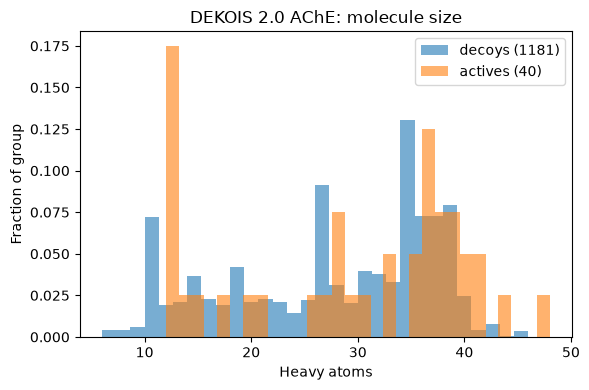

In [5]:
plt.figure(figsize=(6, 4))
decoys = df[df.label == 0]["heavy"]
actives = df[df.label == 1]["heavy"]
plt.hist(decoys, bins=30, alpha=0.6, weights=[1/len(decoys)]*len(decoys), label="decoys (1181)")
plt.hist(actives, bins=30, alpha=0.6, weights=[1/len(actives)]*len(actives), label="actives (40)")
plt.xlabel("Heavy atoms")
plt.ylabel("Fraction of group")
plt.title("DEKOIS 2.0 AChE: molecule size")
plt.legend()
plt.tight_layout()
plt.savefig("../results/dekois_heavy_atoms.png", dpi=150)
plt.show()